# 10. Multinomial Classification (Çoxsinifli Təsnifat) — XGBoost ilə Modelləşdirmə

Maşın öyrənməsində hədəf dəyişən ($y$) iki deyil, **üç və daha çox diskret kateqoriyadan** ($K \ge 3$, məsələn, $y \in \{0, 1, \dots, K-1\}$) ibarət olduqda bu məsələ **Çoxsinifli Təsnifat (Multinomial / Multiclass Classification)** adlanır.

---

### 1. Çoxsinifli Təsnifat Strategiyalarının Müqayisəsi

| Strategiya | İş Prinsipi | Qurulmalı Model Sayı | Əsas Üstünlük və Çatışmazlıq |
| :--- | :--- | :--- | :--- |
| **One-vs-Rest (OvR / OvA)** | Hər bir $k$ sinfini digər bütün siniflərin birləşməsinə qarşı ikili (*binary*) təsnifatçı kimi öyrədir | $K$ ədəd model | Sadədir, lakin hər modeldə sinif balanssızlığı yaranır və ehtimallar cəmi $1$-ə bərabər olmur |
| **One-vs-One (OvO)** | Hər bir mümkün $(k, j)$ sinif cütü üçün ayrıca ikili təsnifatçı qurur | $\frac{K(K-1)}{2}$ ədəd model | Kiçik alt-çoxluqlarda sürətlidir, lakin $K$ böyük olduqda model sayı kvadratik artır |
| **Native Multinomial (Softmax)** | Bütün $K$ sinfi vahid hədəf funksiyası (Çoxsinifli Çarpaz-Entropiya) daxilində eyni vaxtda optimallaşdırır | **Vahid ansambl** (hər boosting addımında $K$ ağac) | Ehtimallar tam kalibrlənmiş olur ($\sum_{k=0}^{K-1} \hat{p}_k = 1$) və siniflərarası rəqabəti birbaşa nəzərə alır |

---

### 2. XGBoost-da Çoxsinifli Təsnifatın Riyazi Aparatı (`multi:softprob` və `mlogloss`)

#### A) Softmax Çevirməsi (`multi:softprob` vs `multi:softmax`)
$K$ sinifli məsələdə **XGBoost** hər bir $t$-ci boosting iterasiyasında paralel olaraq $K$ ədəd qərar ağacı qurur. $i$-ci müşahidə üçün $k$-cı sinfə aid ağacların topladığı xam loqit (*raw margin score*) dəyərini $z_{i,k} = \sum_{t=1}^{M} f_{t,k}(\mathbf{x}_i)$ ilə işarə etsək, modelin $k$-cı sinif üçün verdiyi **Softmax ehtimalı** aşağıdakı kimi hesablanır:

$\displaystyle P(y_i = k \mid \mathbf{x}_i) = \hat{p}_{i,k} = \text{Softmax}(z_{i,k}) = \frac{e^{z_{i,k}}}{\sum_{j=0}^{K-1} e^{z_{i,j}}}, \qquad \sum_{k=0}^{K-1} \hat{p}_{i,k} = 1$

XGBoost-da iki çoxsinifli hədəf (*objective*) rejimi mövcuddur:
* **`objective='multi:softmax'`**: Yalnız ən yüksək ehtimala malik olan sinfin etiketini qaytarır: $\hat{y}_i = \arg\max_{k \in \{0,\dots,K-1\}} \hat{p}_{i,k}$.
* **`objective='multi:softprob'`**: Hər bir müşahidə üçün uzunluğu $K$ olan tam ehtimal vektorunu ($[\hat{p}_{i,0},\, \hat{p}_{i,1},\, \dots,\, \hat{p}_{i,K-1}]$) qaytarır. Bu rejim həm sinif etiketlərini (`predict`), həm də ehtimalları (`predict_proba`) əldə etməyə imkan verdiyi üçün daha universaldır.

#### B) Çoxsinifli Log-İtki Funksiyası (`eval_metric='mlogloss'`)
Model təlim zamanı **Çoxsinifli Çarpaz-Entropiya (Multiclass Cross-Entropy / Log-Loss)** funksiyasını minimallaşdırır:

$\displaystyle \mathcal{L}_{\text{mlogloss}} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=0}^{K-1} y_{i,k} \ln(\hat{p}_{i,k})$

Burada $y_{i,k} \in \{0, 1\}$ *one-hot* indikatorudur ($i$-ci nümunənin həqiqi sinfi $k$ olduqda $y_{i,k}=1$, əks halda $0$). Hər bir $k$ sinfi üzrə birinci tərtib qradiyent ($g_{i,k}$) və ikinci tərtib Hessian ($h_{i,k}$) analitik olaraq çox sadə ifadə olunur:

$\displaystyle g_{i,k} = \frac{\partial \mathcal{L}_i}{\partial z_{i,k}} = \hat{p}_{i,k} - y_{i,k}, \qquad h_{i,k} = \frac{\partial^2 \mathcal{L}_i}{\partial z_{i,k}^2} = \hat{p}_{i,k}(1 - \hat{p}_{i,k})$

## 1. Lazımi Kitabxanaların İmport Edilməsi

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

from sklearn import datasets
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    log_loss,
    roc_curve,
    auc
)

import xgboost as xgb
from xgboost import XGBClassifier

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 110

## 2. Verilənlər Bazasının Yüklənməsi və Kəşfiyyat Təhlili (Iris Dataset)

Ronald Fisher tərəfindən təqdim edilmiş **Iris (Süsən çiçəyi)** verilənlər bazası **150 nümunədən**, **4 fasiləsiz morfoloji əlamətdən** və **3 hədəf sinifdən** ibarətdir:

**Əlamətlər ($X$):**
1. **`sepal length (cm)`:** Kasayarpağının uzunluğu (sm).
2. **`sepal width (cm)`:** Kasayarpağının eni (sm).
3. **`petal length (cm)`:** Ləçəyin uzunluğu (sm).
4. **`petal width (cm)`:** Ləçəyin eni (sm).

**Hədəf Siniflər (`target` — $y \in \{0, 1, 2\}$):**
* **`0` — *Iris setosa*** (50 nümunə — $33.3\%$)
* **`1` — *Iris versicolor*** (50 nümunə — $33.3\%$)
* **`2` — *Iris virginica*** (50 nümunə — $33.3\%$)

In [2]:
# Iris verilənlər bazasının DataFrame şəklində yüklənməsi və sinif adlarının çıxarılması
iris_bunch = datasets.load_iris(as_frame=True)
iris = iris_bunch.frame
class_names = list(iris_bunch.target_names)  # ['setosa', 'versicolor', 'virginica']
iris

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [3]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 5.4 KB


In [4]:
target = 'target'

In [5]:
# Hədəf dəyişənin siniflər üzrə paylanma nisbəti (tam balanslı: hər sinif 33.3%)
iris[target].value_counts(normalize=True).round(2)

target
0    0.33
1    0.33
2    0.33
Name: proportion, dtype: float64

## 3. Verilənlərin Təlim və Test Dəstlərinə Bölünməsi

Verilənləri **80% təlim (`X_train` — 120 nümunə)** və **20% test (`X_test` — 30 nümunə)** hissələrinə bölürük.

> **Niyə `stratify=y` vacibdir?** Təsadüfi bölgü zamanı kiçik həcmli verilənlər bazalarında siniflərdən birinin test dəstinə az və ya çox düşmə ehtimalı var. `stratify=y` parametri təmin edir ki, həm təlim dəstində ($40, 40, 40$), həm də test dəstində ($10, 10, 10$) hər üç sinif tam bərabər ($33.3\%$) nisbətdə təmsil olunsun.

In [6]:
features = iris.drop(columns=[target]).columns.to_list()
X = iris[features]
y = iris[target]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y
)

print(f"Train set ölçüsü: {X_train.shape}")
print(f"Test set ölçüsü: {X_test.shape}")

Train set ölçüsü: (120, 4)
Test set ölçüsü: (30, 4)


## 4. XGBoost Təlimi (Multinomial Classification) və Çarpaz Doğrulama

`XGBClassifier` modelini aşağıdakı konfiqurasiya ilə qururuq:
* **`objective='multi:softprob'`**: Softmax funksiyası vasitəsilə hər 3 sinif üzrə ehtimal paylanmasını hesablayır.
* **`num_class=3`**: Siniflərin ümumi sayını ($K = 3$) bildirir.
* **`n_estimators=100`**: Hər sinif üçün 100 ardıcıl ağac (cəmi $100 \times 3 = 300$ ağac) qurulur.
* **`learning_rate=0.1`**, **`max_depth=3`**: Kiçik həcmli cədvəldə *overfitting*-in qarşısını almaq üçün ağac dərinliyi `3` ilə məhdudlaşdırılır.
* **`eval_metric='mlogloss'`** və **`eval_set=[(X_train, y_train), (X_test, y_test)]`**: Hər boosting iterasiyasında həm təlim, həm də test dəsti üzrə çoxsinifli log-itki (`mlogloss`) dəyərini qeydə alır.

### Stratified K-Fold Çarpaz Doğrulama (`n_splits=10`)
Yalnız tək bir 80/20 bölgüsü ilə kifayətlənməyib, modelin ümumiləşdirmə qabiliyyətini yoxlamaq üçün **10-Qatlı Stratifikasiyalı Çarpaz Doğrulama (`StratifiedKFold`)** tətbiq edirik. Hər qatda 135 nümunə təlim, 15 nümunə (hər sinifdən 5 nümunə) isə doğrulama üçün istifadə olunur.

In [8]:
model = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=123,
    eval_metric='mlogloss'
)

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


In [9]:
# 10-Qatlı Stratifikasiyalı Çarpaz Doğrulama (Stratified 10-Fold Cross-Validation)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)
cv_scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
print(f"10-Fold Cross-Validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

10-Fold Cross-Validation Accuracy: 0.9533 (+/- 0.0521)


## 5. Sinif və Ehtimal Proqnozlarının Alınması (`predict` vs `predict_proba`)

* **`y_proba = model.predict_proba(X_test)`**: Hər bir test nümunəsi üçün $(30 \times 3)$ ölçülü Softmax ehtimal matrisini qaytarır (`prob_class_0 + prob_class_1 + prob_class_2 = 1.0`).
* **`y_pred = model.predict(X_test)`**: Hər sətir üzrə ən yüksək ehtimala malik olan sinif indeksini ($\arg\max_k \hat{p}_{i,k}$) seçir.

> **Nümunə Təhlili (`pred_df.head(10)`):** İlk 10 test nümunəsindən 9-u yüksək əminliklə ($\hat{p} > 0.88$) düzgün təsnif edilmişdir. Yalnız `8`-ci indeksli nümunədə həqiqi sinif `2` (*virginica*) olduğu halda, model `0.6834` ehtimalla `1` (*versicolor*) və `0.2899` ehtimalla `2` (*virginica*) proqnozlaşdırmışdır (sərhəd bölgəsində yerləşən nümunə).

In [11]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

pd.DataFrame(y_proba).head()

,0,1,2
0,0.006378,0.980411,0.013210
1,0.991310,0.006627,0.002063
2,0.002055,0.002769,0.995176
3,0.002147,0.004495,0.993358
4,0.991310,0.006627,0.002063


In [12]:
pred_df = pd.DataFrame(y_proba, columns=[f'prob_class_{i}' for i in range(3)])
pred_df.head()

,prob_class_0,prob_class_1,prob_class_2
0,0.006378,0.980411,0.013210
1,0.991310,0.006627,0.002063
2,0.002055,0.002769,0.995176
3,0.002147,0.004495,0.993358
4,0.991310,0.006627,0.002063


In [13]:
pred_df['predict'] = y_pred
pred_df['actual'] = y_test.values
pred_df.head(10)

,prob_class_0,prob_class_1,prob_class_2,predict,actual
0,0.006378,0.980411,0.013210,1,1
1,0.991310,0.006627,0.002063,0,0
2,0.002055,0.002769,0.995176,2,2
3,0.002147,0.004495,0.993358,2,2
4,0.991310,0.006627,0.002063,0,0
5,0.991310,0.006627,0.002063,0,0
6,0.001804,0.002103,0.996093,2,2
7,0.007898,0.888759,0.103343,1,1
8,0.026690,0.683434,0.289876,1,2
9,0.991310,0.006627,0.002063,0,0


## 6. Çoxsinifli Qarışıqlıq Matrisi ($K \times K$ Confusion Matrix)

$K=3$ sinifli məsələdə Qarışıqlıq Matrisi $C \in \mathbb{N}^{3 \times 3}$ ölçülü cədvəldir. Burada $C_{r, c}$ elementi həqiqi sinfi $r$ (`Actual`) olub, model tərəfindən $c$ (`Predicted`) kimi proqnozlaşdırılan nümunələrin sayını göstərir:

* **Baş diaqonal elementləri ($C_{k,k}$):** Düzgün təsnif edilmiş nümunələr ($10 + 9 + 9 = 28$).
* **Diaqonaldan kənar elementlər ($C_{r,c},\, r \neq c$):** Səhv təsnif edilmiş nümunələr ($1 + 1 = 2$).

Hər bir $k$ sinfi üçün **One-vs-Rest** prinsipinə görə:
* **True Positive ($\text{TP}_k$):** $C_{k,k}$ ($k$-cı sətir və $k$-cı sütunun kəsişməsi).
* **False Positive ($\text{FP}_k$):** $\sum_{r \neq k} C_{r,k}$ ($k$-cı sütundakı digər elementlərin cəmi — digər siniflərin səhvən $k$ kimi proqnozlaşdırılması).
* **False Negative ($\text{FN}_k$):** $\sum_{c \neq k} C_{k,c}$ ($k$-cı sətirdəki digər elementlərin cəmi — həqiqi $k$ sinfinin başqa sinif kimi proqnozlaşdırılması).
* **Ümumi Dəqiqlik ($\text{Accuracy}$):**
  $\displaystyle \text{Accuracy} = \frac{\sum_{k=0}^{K-1} C_{k,k}}{\sum_{r=0}^{K-1}\sum_{c=0}^{K-1} C_{r,c}} = \frac{10 + 9 + 9}{30} = \frac{28}{30} \approx 0.9333 \text{ (93.33\%)}$

In [14]:
actual = y_test.values
pred_class = y_pred

y_true = np.asarray(actual, dtype=int)
y_preds = np.asarray(pred_class, dtype=int)

cm = confusion_matrix(y_true, y_preds, labels=[0, 1, 2])
cm

array([[10,  0,  0],
       [ 0,  9,  1],
       [ 0,  1,  9]], dtype=int64)

In [15]:
labeled_classes = [f"{i} ({name})" for i, name in enumerate(class_names)]

cm_df = pd.DataFrame(
    cm,
    index=pd.Index(labeled_classes, name="Actual"),
    columns=pd.Index(labeled_classes, name="Predicted")
)
cm_df

Predicted,0 (setosa),1 (versicolor),2 (virginica)
Actual,,,
0 (setosa),10,0,0
1 (versicolor),0,9,1
2 (virginica),0,1,9


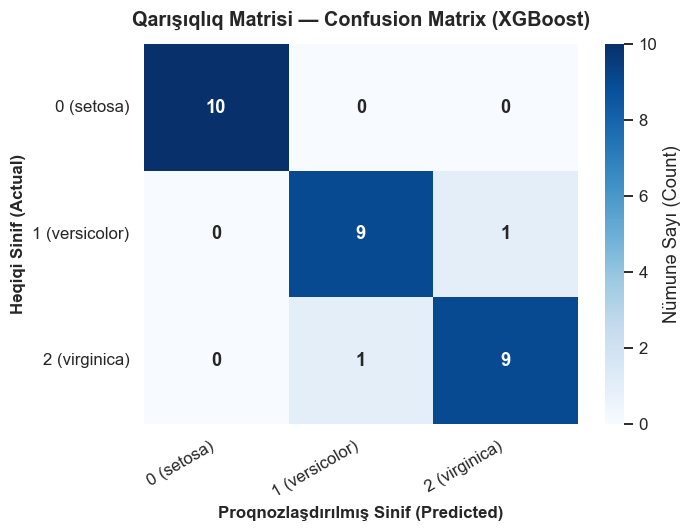

In [16]:
plt.figure(figsize=(6.5, 5))
ax = sns.heatmap(
    cm_df,
    annot=True, fmt="d",
    cmap="Blues", vmin=0,
    annot_kws={"size": 12, "weight": "bold"},
    cbar_kws={"label": "Nümunə Sayı (Count)"}
)
ax.set_xlabel("Proqnozlaşdırılmış Sinif (Predicted)", fontsize=11, fontweight="bold")
ax.set_ylabel("Həqiqi Sinif (Actual)", fontsize=11, fontweight="bold")
ax.set_title("Qarışıqlıq Matrisi — Confusion Matrix (XGBoost)", fontsize=13, fontweight="bold", pad=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

In [17]:
manual_acc = (10 + 9 + 9) / (10 + 9 + 9 + 1 + 1)
acc_score = accuracy_score(y_test, y_pred)
test_logloss = log_loss(y_test, y_proba)

print(f"Manual Accuracy:   {manual_acc:.4f}")
print(f"Sklearn Accuracy:  {acc_score:.4f}")
print(f"Test Multiclass Log-Loss (mlogloss): {test_logloss:.4f}")

Manual Accuracy:   0.9333
Sklearn Accuracy:  0.9333
Test Multiclass Log-Loss (mlogloss): 0.2474


## 7. Model Qiymətləndirilməsi (`Classification Report`) və Əhəmiyyətli Xüsusiyyətlər (`Feature Importance`)

### A) Çoxsinifli `Classification Report` Metrikalarının Riyazi İzahı
Hər bir $k \in \{0, 1, 2\}$ sinfi üçün:

$\displaystyle \text{Precision}_k = \frac{\text{TP}_k}{\text{TP}_k + \text{FP}_k}, \qquad \text{Recall}_k = \frac{\text{TP}_k}{\text{TP}_k + \text{FN}_k}, \qquad F_{1,k} = \frac{2 \cdot \text{Precision}_k \cdot \text{Recall}_k}{\text{Precision}_k + \text{Recall}_k}$

* **Sinif `0` (*setosa*):** $\text{TP}_0=10,\, \text{FP}_0=0,\, \text{FN}_0=0 \implies \text{Precision}=1.00,\, \text{Recall}=1.00,\, F_1=1.00$.
* **Sinif `1` (*versicolor*) və Sinif `2` (*virginica*):** $\text{TP}=9,\, \text{FP}=1,\, \text{FN}=1 \implies \text{Precision}=0.90,\, \text{Recall}=0.90,\, F_1=0.90$.
* **Macro Average (`macro avg`):** Bütün siniflərin metrikalarının sadə ədədi ortasıdır (siniflərin həcmindən asılı olmayaraq hər sinfə bərabər çəki verir):
  $\displaystyle \text{Macro-}F_1 = \frac{1}{K} \sum_{k=0}^{K-1} F_{1,k} = \frac{1.00 + 0.90 + 0.90}{3} = 0.9333$
* **Weighted Average (`weighted avg`):** Hər sinfin metrikasını həmin sinfin test dəstindəki nümunə sayına (`support` — $N_k$) görə çəkiləndirərək hesablayır:
  $\displaystyle \text{Weighted-}F_1 = \sum_{k=0}^{K-1} \frac{N_k}{N} F_{1,k}$

---

### B) XGBoost Əlamət Əhəmiyyətliliyi (`importance_type='gain'`)
XGBoost-da əlamətlərin əhəmiyyətliliyi 3 fərqli meyarla ölçülə bilər:
1. **`weight`**: Əlamətin bütün ağaclarda budaqlanma (*split*) nöqtəsi kimi neçə dəfə istifadə edildiyini sayır.
2. **`gain` (Tövsiyə olunan əsas meyar):** Həmin əlamət üzrə aparılan budaqlanmaların hədəf itki funksiyasını (`mlogloss`) orta hesabla nə qədər azaltdığını ölçür.
3. **`cover`**: Həmin əlamətlə bölünən düyünlərə düşən müşahidələrin (Hessian çəkilərinin) orta sayını göstərir.

> **Texniki Düzəliş:** `xgb.plot_importance(model, ...)` funksiyası daxildə özü yeni `figure` yaradır; əvvəlcədən `plt.figure(figsize=(8, 4))` çağırıldıqda və `ax` arqumenti ötürülmədikdə ekranda boş `<Figure size 800x400 with 0 Axes>` qalır. Aşağıdakı kodda `fig, axes = plt.subplots(1, 2, figsize=(14, 5))` yaradılaraq `ax=axes[0]` birbaşa ötürülmüş, sağ tərəfdə (`axes[1]`) isə təlim və test dəstləri üzrə **`mlogloss` Öyrənmə Əyrisi (Learning Curve)** əlavə edilmişdir.

In [18]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=labeled_classes))

Classification Report:

                precision    recall  f1-score   support

    0 (setosa)       1.00      1.00      1.00        10
1 (versicolor)       0.90      0.90      0.90        10
 2 (virginica)       0.90      0.90      0.90        10

      accuracy                           0.93        30
     macro avg       0.93      0.93      0.93        30
  weighted avg       0.93      0.93      0.93        30



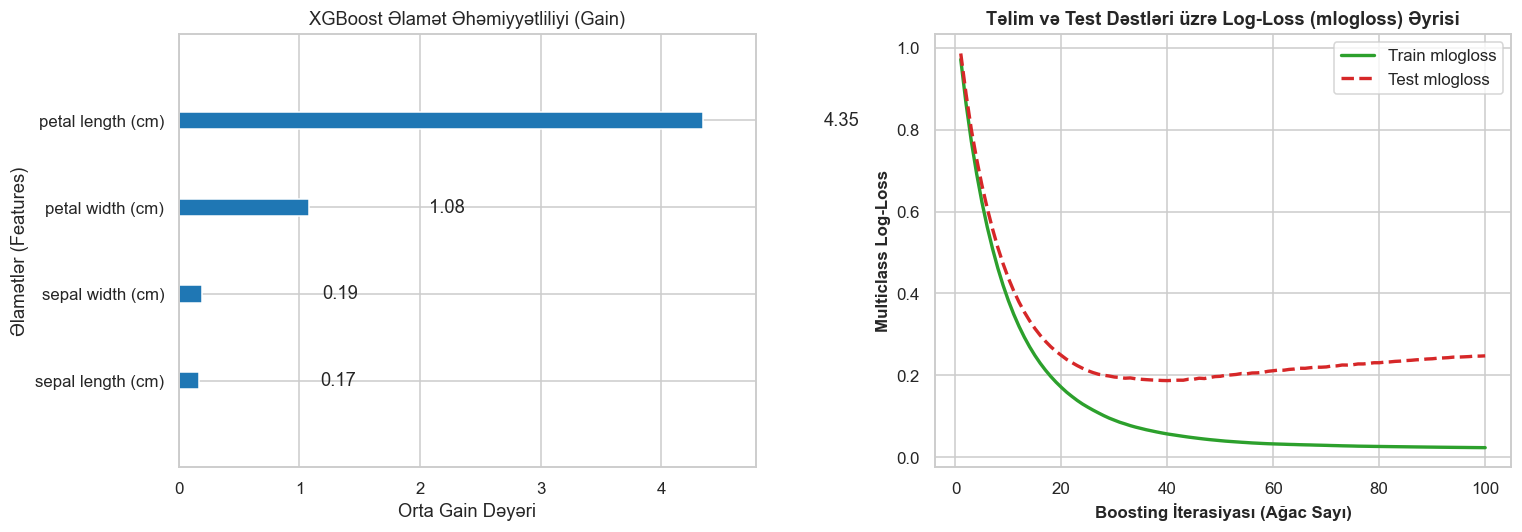

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol Qrafik: XGBoost Feature Importance (Gain) — boş fiqur yaranmaması üçün ax=axes[0] ötürülür
xgb.plot_importance(
    model,
    importance_type='gain',
    ax=axes[0],
    title='XGBoost Əlamət Əhəmiyyətliliyi (Gain)',
    xlabel='Orta Gain Dəyəri',
    ylabel='Əlamətlər (Features)',
    values_format='{v:.2f}',
    color='#1f77b4'
)

# Sağ Qrafik: İterasiyalar üzrə Təlim və Test Multiclass Log-Loss (mlogloss) Öyrənmə Əyrisi
results = model.evals_result()
epochs = range(1, len(results['validation_0']['mlogloss']) + 1)

sns.lineplot(x=epochs, y=results['validation_0']['mlogloss'], ax=axes[1], label='Train mlogloss', linewidth=2.2, color='#2ca02c')
sns.lineplot(x=epochs, y=results['validation_1']['mlogloss'], ax=axes[1], label='Test mlogloss', linewidth=2.2, color='#d62728', linestyle='--')
axes[1].set_title('Təlim və Test Dəstləri üzrə Log-Loss (mlogloss) Əyrisi', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Boosting İterasiyası (Ağac Sayı)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Multiclass Log-Loss', fontsize=11, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()